# 08 – Scénarios 2027 et tableau de bord

**Objectif :** une page web interactive où l'on choisit un **département**, un **niveau de scénario** (optimiste, central, pessimiste) et une **semaine de 2027**, et où la carte montre les communes à surveiller.

## Leçon 1 – Prévision vs scénario (rappel)

Pour un jour de 2027, le modèle aurait besoin de la météo de ce jour : **elle n'existe pas encore**. Comme en planification de la demande, on construit des **scénarios** : *« dans une année typique, quelles communes faut-il surveiller, et à partir de quelle semaine ? Et dans une mauvaise année, une sur dix ? »*

## Leçon 2 – Un ensemble de 30 années de météo

Dans le projet 13, on rejouait la météo des 10 années 2016-2025. Avec 10 valeurs, un « P10 » ou un « P90 » repose sur **une seule** année : c'est fragile.

Ici, on profite de SIM2 : on rejoue la météo réelle de **30 années (1996-2025)**. Le modèle a été **entraîné** sur 2016-2025 (les années où l'on connaît les feux) ; pour le **faire tourner**, il n'a besoin que de la météo, et celle-ci existe depuis 1958.

Pour chaque commune et chaque semaine, on obtient 30 valeurs, résumées par des **quantiles** :
- **P10 – optimiste** : seules 3 années sur 30 font mieux ;
- **P50 – central** : l'année typique (la médiane) ;
- **P90 – pessimiste** : le risque d'une année sur 10.

In [1]:
import json
import time
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier

sauvegarde = joblib.load("../data/processed/modele_2016_2022.joblib")
FEATURES, REGLAGES = sauvegarde["features"], sauvegarde["reglages"]
print(REGLAGES)

df = pd.read_parquet("../data/processed/features_med.parquet", columns=["code", "dept", "jour", "feu"] + FEATURES)
communes = pd.read_csv("../data/processed/communes_med.csv", dtype={"code": str, "dept": str})
print(df.shape)

{'learning_rate': 0.05, 'max_iter': 500, 'early_stopping': False, 'max_leaf_nodes': 15, 'min_samples_leaf': 5000, 'random_state': 42}


(12803765, 30)


On recharge les **features** et les **réglages** sauvegardés au notebook 06 : pas de risque de se tromper en les recopiant.

## Étape 1 – Réentraîner sur toutes les données (2016-2025)

Au notebook 06, on a gardé 2023-2025 sous clé pour **mesurer** honnêtement le modèle. Maintenant, pour **s'en servir**, on veut qu'il ait vu le plus d'exemples possible : on le réentraîne sur **2016-2025**, avec exactement les mêmes features et réglages (et le même sous-échantillonnage pondéré).

In [2]:
garde = (df["feu"] == 1) | (np.random.default_rng(42).random(len(df)) < 0.10)
ech = df[garde]
poids = np.where(ech["feu"] == 1, 1, 10)

debut = time.time()
modele = HistGradientBoostingClassifier(**REGLAGES)
modele.fit(ech[FEATURES], ech["feu"], sample_weight=poids)
print(f"Modèle entraîné sur {len(ech):,} lignes ({ech['feu'].sum()} jours avec feu) en {time.time() - debut:.0f} s")

Modèle entraîné sur 1,293,226 lignes (15404 jours avec feu) en 53 s


## Étape 2 – Fabriquer les features « 2027 » à partir d'une année de météo

Pour rejouer la météo de l'année Y :
1. on prend les **features météo** de chaque point SAFRAN en Y (calculées au notebook 04) ;
2. on les copie vers les communes (chaque commune → son point) ;
3. on garde le **calendrier** de Y.

On **remplace** les features d'historique par la situation **connue fin 2025** :
- `feux_commune_365j` → jours avec feu de la commune **en 2025** ;
- `taux_feu_commune` → son taux sur **2016-2025** ;
- `feux_dept_veille`, `feux_zone_veille` → on ne connaît pas les feux de 2027 : on met la **moyenne observée pour ce jour de l'année** sur 2016-2025.

### Leçon 3 – Ne pas tricher, même dans un scénario
Pourquoi ne pas garder les vrais `feux_dept_veille` de 2022 ? Parce qu'ils contiennent **les feux de 2022** : rejouer 2022 reviendrait à savoir d'avance qu'il y aura beaucoup de feux. On ne rejoue que ce qu'on pourrait vraiment supposer : la **météo**. (Et pour 1996-2015, on n'a de toute façon pas ces informations.)

In [3]:
meteo = pd.read_parquet("../data/processed/meteo_features_points_med.parquet")
meteo["annee"] = meteo["jour"].dt.year
print(meteo.shape, meteo["annee"].min(), "→", meteo["annee"].max())

# situation connue fin 2025
df["annee"] = df["jour"].dt.year
feux_2025 = df[df["annee"] == 2025].groupby("code")["feu"].sum()
jours_total = df.groupby("code")["feu"].agg(["sum", "size"])
taux_fin_2025 = (jours_total["sum"] + 365 * 0.001) / (jours_total["size"] + 365)

df["jour_annee"] = df["jour"].dt.day_of_year
dept_typique = df.groupby(["dept", "annee", "jour_annee"], observed=True)["feu"].sum().groupby(["dept", "jour_annee"], observed=True).mean()
dept_typique = dept_typique.groupby(level="dept", observed=True).shift(1).fillna(0).rename("feux_dept_veille").reset_index()
dept_typique["dept"] = dept_typique["dept"].astype(str)
zone_typique = df.groupby(["annee", "jour_annee"])["feu"].sum().groupby("jour_annee").mean().shift(1).fillna(0)

base = communes[["code", "dept", "lat", "lon", "LAMBX", "LAMBY"]].copy()
base["log_densite"] = np.log1p(communes["densite"])
base["feux_commune_365j"] = base["code"].map(feux_2025).fillna(0)
base["taux_feu_commune"] = base["code"].map(taux_fin_2025)

def features_meteo(annee):
    m = meteo[meteo["annee"] == annee]
    X = base.merge(m, on=["LAMBX", "LAMBY"], how="left")
    X["mois"] = X["jour"].dt.month
    X["jour_annee"] = X["jour"].dt.day_of_year
    X["jour_semaine"] = X["jour"].dt.day_of_week
    X["week_end"] = (X["jour_semaine"] >= 5).astype(int)
    X = X.merge(dept_typique, on=["dept", "jour_annee"], how="left")
    X["feux_zone_veille"] = X["jour_annee"].map(zone_typique)
    return X

exemple = features_meteo(2022)
print(exemple.shape, "valeurs manquantes :", exemple[FEATURES].isna().sum().sum())

(13313970, 20) 1996 → 2025


(1279325, 33) valeurs manquantes : 0


`shift(1)` sur la moyenne par jour de l'année : `feux_dept_veille` du 15 juillet = moyenne des feux du **14** juillet. On garde la même définition qu'à l'entraînement.

Attendu : 3 505 communes × 365 jours = 1 279 325 lignes, 0 valeur manquante.

## Étape 3 – Faire tourner les 30 années

### Leçon 4 – Probabilité d'au moins un feu dans la semaine (rappel)
Pas de feu un jour = `1 − p` ; aucun feu sur 7 jours = `(1 − p₁) × … × (1 − p₇)` ; au moins un = `1 − ce produit`. Les 1 ou 2 derniers jours de l'année sont rattachés à la semaine 52.

### Leçon 5 – Ne garder que les résumés
30 années × 1,3 million de lignes = 38 millions de prédictions. On ne les garde pas toutes en mémoire : pour chaque année, on calcule tout de suite les **résumés** (par commune × semaine, par commune sur la saison…), qu'on range dans des tableaux `numpy` à 3 dimensions : `[année de météo, commune, semaine]`.

In [4]:
ANNEES_METEO = list(range(1996, 2026))
CODES = base["code"].tolist()
DEPTS = sorted(base["dept"].unique())
dept_de = base["dept"].values

proba_sem = np.zeros((len(ANNEES_METEO), len(CODES), 52))     # P(≥ 1 feu dans la semaine)
attendus_sem = np.zeros((len(ANNEES_METEO), len(CODES), 52))   # jours avec feu attendus
saison_jours = np.zeros((len(ANNEES_METEO), len(CODES)))       # juin → septembre
saison_proba = np.zeros((len(ANNEES_METEO), len(CODES)))
annuel = np.zeros((len(ANNEES_METEO), len(CODES)))

debut = time.time()
for i, annee in enumerate(ANNEES_METEO):
    X = features_meteo(annee)
    X["proba"] = modele.predict_proba(X[FEATURES])[:, 1]
    X["semaine"] = ((X["jour_annee"] - 1) // 7 + 1).clip(upper=52)
    X["log_pas_de_feu"] = np.log1p(-X["proba"])
    X["ete"] = X["mois"].between(6, 9)

    par_sem = X.groupby(["code", "semaine"]).agg(lp=("log_pas_de_feu", "sum"), att=("proba", "sum"))
    proba_sem[i] = (1 - np.exp(par_sem["lp"])).unstack().loc[CODES].values
    attendus_sem[i] = par_sem["att"].unstack().loc[CODES].values

    ete = X[X["ete"]].groupby("code").agg(lp=("log_pas_de_feu", "sum"), att=("proba", "sum")).loc[CODES]
    saison_jours[i] = ete["att"].values
    saison_proba[i] = 1 - np.exp(ete["lp"].values)
    annuel[i] = X.groupby("code")["proba"].sum().loc[CODES].values
    if annee % 5 == 0:
        print(f"{annee} fait ({time.time() - debut:.0f} s)")

2000 fait (81 s)


2005 fait (155 s)


2010 fait (230 s)


2015 fait (323 s)


2020 fait (438 s)


2025 fait (522 s)


**Astuce numérique :** au lieu de multiplier 7 (ou 122) nombres proches de 1, on additionne leurs **logarithmes** (`log1p(-p)` = log(1 − p)), puis on repasse à l'exponentielle. Mathématiquement c'est pareil (log(a × b) = log a + log b), mais c'est plus rapide avec `groupby` et plus précis.

## Étape 4 – Le bilan par année de météo

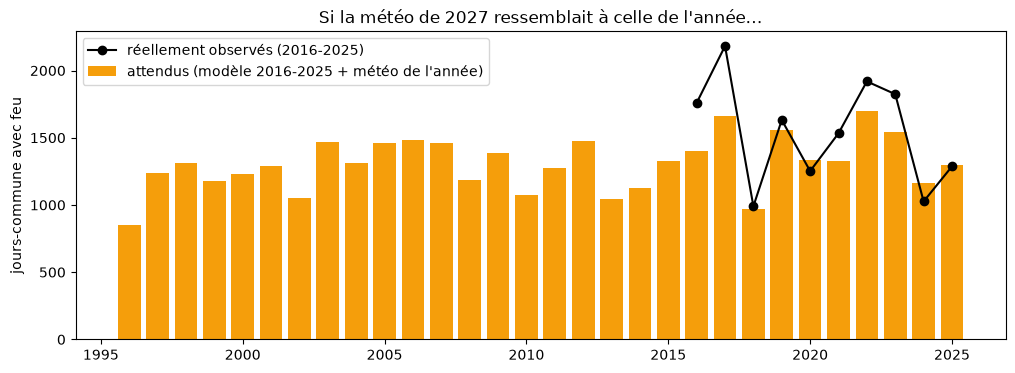

,attendus sur l'année,dont juin-sept.,réel (jours-commune)
année de météo,,,
1996,851.0,523.0,NaN
2018,969.0,632.0,990.0
2013,1043.0,670.0,NaN
2002,1052.0,554.0,NaN
2010,1077.0,737.0,NaN
2014,1123.0,620.0,NaN
2024,1163.0,692.0,1026.0
1999,1176.0,678.0,NaN
2008,1186.0,661.0,NaN


In [5]:
bilan = pd.DataFrame({"année de météo": ANNEES_METEO,
                      "attendus sur l'année": annuel.sum(axis=1),
                      "dont juin-sept.": saison_jours.sum(axis=1)}).set_index("année de météo")
reel = df.groupby("annee")["feu"].sum()
bilan["réel (jours-commune)"] = reel

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(bilan.index, bilan["attendus sur l'année"], color="#f59e0b", label="attendus (modèle 2016-2025 + météo de l'année)")
ax.plot(reel.index, reel.values, "o-", color="black", label="réellement observés (2016-2025)")
ax.set_ylabel("jours-commune avec feu")
ax.set_title("Si la météo de 2027 ressemblait à celle de l'année…")
ax.legend()
plt.show()
bilan.round(0).sort_values("attendus sur l'année")

**Comment lire ce graphique ?** Chaque barre répond à : *« avec l'historique de feux connu fin 2025, combien de jours-commune avec feu attendrait-on en 2027 si la météo était celle de telle année ? »*

- La **fourchette** est large : la météo seule fait varier l'année du simple à près du double.
- Les points noirs (réalité 2016-2025) suivent globalement les barres, sans être identiques : la météo n'explique pas tout (contexte humain, historique de feux de l'année…).

### Leçon 5 bis – Le réchauffement se voit dans l'ensemble
On regroupe les 30 années de météo par **décennie** et on compare les feux attendus (avec le même modèle et le même historique de communes : seule la météo change).

In [6]:
decennie = pd.cut(bilan.index, bins=[1995, 2005, 2015, 2025], labels=["1996-2005", "2006-2015", "2016-2025"])
par_decennie = bilan.groupby(decennie, observed=True)[["attendus sur l'année", "dont juin-sept."]].mean().round(0)
par_decennie["réel moyen"] = [np.nan, np.nan, round(reel.mean())]
par_decennie

,attendus sur l'année,dont juin-sept.,réel moyen
1996-2005,1240.0,723.0,NaN
2006-2015,1283.0,762.0,NaN
2016-2025,1396.0,828.0,1540.0


**Lecture :** avec exactement le même modèle et les mêmes communes, la météo des années 1996-2005 donne en moyenne **1 240** jours-commune avec feu par an, celle de 2006-2015 **1 283**, et celle de 2016-2025 **1 396** : **+13 %** entre la première et la dernière décennie (+15 % l'été). Les étés récents sont plus chauds et plus secs : c'est le **réchauffement climatique**, vu à travers le modèle.

Deux conséquences pour nos scénarios :
1. le scénario central sur 30 ans (≈ 800 jours-commune avec feu de juin à septembre) est **prudent** : il mélange des étés des années 1990, en moyenne plus cléments que ceux qu'on peut attendre en 2027 ;
2. même avec la météo de 2016-2025, le modèle attend 1 396 jours avec feu par an, alors qu'il y en a eu **1 540** (−9 %). Pourquoi ? Dans un scénario, on remplace `feux_dept_veille` et `feux_zone_veille` par une **moyenne**. On efface ainsi les journées d'« emballement » où les feux s'enchaînent (le 8 juillet 2025, 30 communes ont brûlé). Or le risque grimpe **plus que proportionnellement** ces jours-là : la moyenne des risques est plus grande que le risque calculé sur une situation moyenne.

👉 On garde les 30 années pour bien mesurer l'**incertitude** (la largeur de la fourchette), mais on lit le niveau du scénario central comme un **plancher** plutôt qu'une prévision. Pistes : ne garder que les 15-20 dernières années, ou les pondérer davantage.

## Étape 5 – Les quantiles

`np.quantile(tableau, [0.1, 0.5, 0.9], axis=0)` calcule les 3 quantiles **le long de la dimension « année de météo »**, pour chaque commune et chaque semaine d'un coup.

In [7]:
Q = [0.1, 0.5, 0.9]
NIV = ["p10", "p50", "p90"]
q_sem = np.quantile(proba_sem, Q, axis=0)          # forme : (3, communes, 52)
q_saison_jours = np.quantile(saison_jours, Q, axis=0)
q_saison_proba = np.quantile(saison_proba, Q, axis=0)
q_annuel = np.quantile(annuel, Q, axis=0)

i_mart = CODES.index("13056")
pd.DataFrame(q_sem[:, i_mart, 25:32].T, columns=NIV, index=range(26, 33)).style.format("{:.0%}")

,p10,p50,p90
26,37%,59%,69%
27,44%,63%,78%
28,48%,65%,77%
29,50%,67%,76%
30,47%,66%,76%
31,42%,61%,72%
32,38%,57%,73%


Lecture pour Martigues en juillet : même dans le scénario optimiste, la probabilité d'au moins un départ de feu dans la semaine reste élevée.

### Le total d'un département ou de la zone
Rappel : on **ne peut pas additionner** les P90 des communes, car toutes ne vivent pas leur « mauvaise année » en même temps. On calcule le total **pour chaque année de météo**, puis les quantiles de ces totaux.

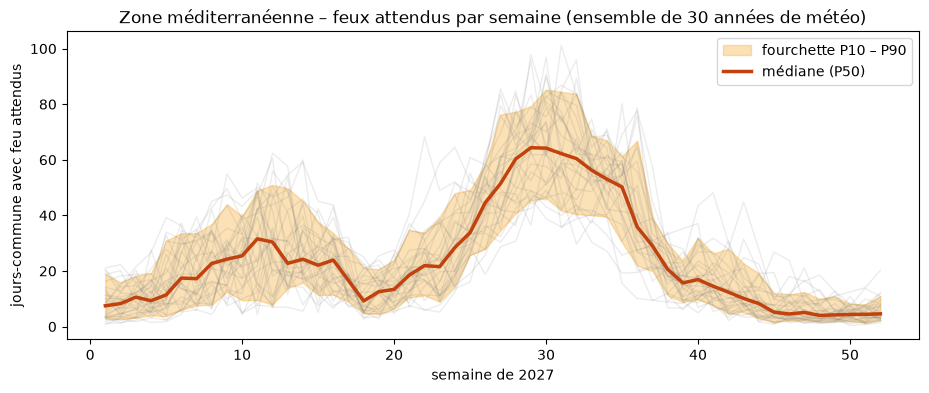

Juin-septembre : {'p10': 614, 'p50': 799, 'p90': 913}


In [8]:
def zone_quantiles(masque):
    par_semaine = attendus_sem[:, masque, :].sum(axis=1)        # (30 années, 52 semaines)
    par_saison = saison_jours[:, masque].sum(axis=1)            # (30 années,)
    return np.quantile(par_semaine, Q, axis=0), np.quantile(par_saison, Q)

tout = np.ones(len(CODES), dtype=bool)
zone_sem, zone_saison = zone_quantiles(tout)

fig, ax = plt.subplots(figsize=(11, 4))
for i in range(len(ANNEES_METEO)):
    ax.plot(range(1, 53), attendus_sem[i].sum(axis=0), color="grey", alpha=0.15, linewidth=1)
ax.fill_between(range(1, 53), zone_sem[0], zone_sem[2], color="#f59e0b", alpha=0.3, label="fourchette P10 – P90")
ax.plot(range(1, 53), zone_sem[1], color="#c2410c", linewidth=2.5, label="médiane (P50)")
ax.set_xlabel("semaine de 2027")
ax.set_ylabel("jours-commune avec feu attendus")
ax.set_title("Zone méditerranéenne – feux attendus par semaine (ensemble de 30 années de météo)")
ax.legend()
plt.show()
print("Juin-septembre :", {n: round(v) for n, v in zip(NIV, zone_saison)})

- Chaque trait gris = une année de météo rejouée ;
- la **bande orange** = là où se trouvent 80 % des années (P10 → P90) ;
- le **trait foncé** = l'année typique.

On retrouve les **deux saisons** de l'exploration : un premier pic en **mars** (écobuage, surtout en montagne) et le grand pic d'**été**, dont la hauteur dépend beaucoup de la météo (bande très large).

## Étape 6 – Préparer les données de la page web

### Leçon 6 – Tout précalculer, et compacter
La page web ne sait pas exécuter le modèle : on précalcule tout et on le range en JSON. Avec 3 505 communes × 52 semaines × 3 niveaux ≈ 550 000 nombres, chaque caractère compte : on stocke les probabilités hebdomadaires en **pour mille entiers** (`0.0734` → `73`), ce qui divise la taille par ≈ 2.

D'abord l'historique réel de chaque commune (feux rattachés aux communes actuelles, notebook 02) :

In [9]:
feux = pd.read_csv("../data/processed/feux_med.csv", dtype={"code": str}, parse_dates=["date"])
feux["surface_ha"] = feux["Surface parcourue (m2)"] / 10_000
ANNEES = list(range(2016, 2026))

nb_feux = feux.groupby("code").size()
surface_ha = feux.groupby("code")["surface_ha"].sum()
par_annee = feux.groupby(["code", feux["date"].dt.year]).size().unstack(fill_value=0).reindex(columns=ANNEES, fill_value=0)
par_mois = feux.groupby(["code", feux["date"].dt.month]).size().unstack(fill_value=0).reindex(columns=range(1, 13), fill_value=0)
jours_avec_feu = df.groupby("code")["feu"].sum()
ete_reel = df[df["jour"].dt.month.between(6, 9)]
jours_avec_feu_ete = ete_reel.groupby("code")["feu"].sum()

print("Martigues :", nb_feux["13056"], "feux,", round(surface_ha["13056"]), "ha,", jours_avec_feu["13056"], "jours avec feu")

Martigues : 224 feux, 1459 ha, 183 jours avec feu


In [10]:
NOMS_DEPTS = {"04": "Alpes-de-Haute-Provence", "05": "Hautes-Alpes", "06": "Alpes-Maritimes", "07": "Ardèche",
              "11": "Aude", "13": "Bouches-du-Rhône", "26": "Drôme", "2A": "Corse-du-Sud", "2B": "Haute-Corse",
              "30": "Gard", "34": "Hérault", "48": "Lozère", "66": "Pyrénées-Orientales", "83": "Var", "84": "Vaucluse"}
NIVEAUX = [
    {"id": "p10", "nom": "Optimiste", "detail": "seules 3 années sur 30 font mieux"},
    {"id": "p50", "nom": "Central", "detail": "année typique (médiane)"},
    {"id": "p90", "nom": "Pessimiste", "detail": "1 année sur 10 fait pire"},
]
info = communes.set_index("code")

fiche = {}
for c in CODES:
    fiche[c] = {
        "nom": info.loc[c, "nom"], "dept": info.loc[c, "dept"],
        "lat": round(float(info.loc[c, "lat"]), 4), "lon": round(float(info.loc[c, "lon"]), 4),
        "pop": int(info.loc[c, "population"]),
        "feux": int(nb_feux.get(c, 0)), "jours": int(jours_avec_feu.get(c, 0)), "jours_ete": int(jours_avec_feu_ete.get(c, 0)),
        "surface": round(float(surface_ha.get(c, 0)), 1),
        "par_annee": [int(v) for v in par_annee.loc[c]] if c in par_annee.index else [0] * len(ANNEES),
        "par_mois": [int(v) for v in par_mois.loc[c]] if c in par_mois.index else [0] * 12,
    }

zones = {}
for z in ["*"] + DEPTS:
    masque = tout if z == "*" else (dept_de == z)
    q_s, q_sa = zone_quantiles(masque)
    codes_z = [c for c, m in zip(CODES, masque) if m]
    zones[z] = {
        "semaine": {n: [round(float(v), 2) for v in q_s[k]] for k, n in enumerate(NIV)},
        "saison": {n: round(float(q_sa[k]), 1) for k, n in enumerate(NIV)},
        "saison_reel": round(float(jours_avec_feu_ete.loc[codes_z].sum() / len(ANNEES)), 1),
        "feux": int(nb_feux.reindex(codes_z).fillna(0).sum()),
        "jours": int(jours_avec_feu.loc[codes_z].sum()),
    }

donnees = {
    "niveaux": NIVEAUX, "annees": ANNEES,
    "depts": [{"code": d, "nom": NOMS_DEPTS[d]} for d in DEPTS],
    "communes": fiche,
    "semaine": {n: {c: [int(round(v * 1000)) for v in q_sem[k, i]] for i, c in enumerate(CODES)} for k, n in enumerate(NIV)},
    "saison": {n: {c: int(round(q_saison_proba[k, i] * 1000)) for i, c in enumerate(CODES)} for k, n in enumerate(NIV)},
    "saison_jours": {n: {c: round(float(q_saison_jours[k, i]), 2) for i, c in enumerate(CODES)} for k, n in enumerate(NIV)},
    "annuel": {n: {c: round(float(q_annuel[k, i]), 1) for i, c in enumerate(CODES)} for k, n in enumerate(NIV)},
    "zones": zones,
}
print("Martigues, semaine 30 (‰) :", {n: donnees["semaine"][n]["13056"][29] for n in NIV})
print("Zone, juin-sept. :", zones["*"]["saison"], "| réel moyen 2016-2025 :", zones["*"]["saison_reel"])

Martigues, semaine 30 (‰) : {'p10': 473, 'p50': 657, 'p90': 756}
Zone, juin-sept. : {'p10': 613.7, 'p50': 799.3, 'p90': 913.4} | réel moyen 2016-2025 : 893.5


## Étape 7 – Écrire la page

Le gabarit `src/carte_scenarios_template.html` (HTML + JavaScript + la bibliothèque de cartes Leaflet) contient trois « trous » : `__DATA__`, `__GEO__` (les contours simplifiés du notebook 02) et `__PRUDENCE__` (la phrase d'avertissement, écrite à partir des résultats du notebook 07).

In [11]:
contours = json.loads(Path("../data/raw/communes_med.geojson").read_text(encoding="utf-8"))
for f in contours["features"]:
    f["properties"] = {"code": f["properties"]["code"]}   # le nom est déjà dans DATA : on allège

PRUDENCE = ("Sur 2023-2025 (jamais vus à l'entraînement), le modèle classait bien les communes et les périodes à risque "
            "(46 % des feux dans les 5 % de cas jugés les plus risqués, contre 33 % pour une méthode historique simple), "
            "mais le niveau absolu des probabilités est à prendre comme un ordre de grandeur. "
            "Le scénario central est plutôt un plancher : il mélange des étés de 1996 à 2025, en moyenne moins secs "
            "que les étés récents (la météo 2016-2025 donne 13 % de feux attendus de plus que celle de 1996-2005).")

gabarit = Path("../src/carte_scenarios_template.html").read_text(encoding="utf-8")
page = (gabarit
        .replace("__DATA__", json.dumps(donnees, ensure_ascii=False, separators=(",", ":")))
        .replace("__GEO__", json.dumps(contours, ensure_ascii=False, separators=(",", ":")))
        .replace("__PRUDENCE__", PRUDENCE))

sortie = Path("../outputs/carte_scenarios_2027.html")
sortie.parent.mkdir(exist_ok=True)
sortie.write_text(page, encoding="utf-8")
print(f"Page écrite : {sortie.resolve()}  ({sortie.stat().st_size / 1e6:.1f} Mo)")

Page écrite : /Users/duvalthomas/ml-projets/incendies-mediterranee/outputs/carte_scenarios_2027.html  (4.2 Mo)


`separators=(",", ":")` : JSON **compact**, sans les espaces après les virgules et les deux-points. Encore quelques centaines de Ko gagnés.

👉 **Ouvre `outputs/carte_scenarios_2027.html` dans ton navigateur** et explore :
- choisis un **département** dans la liste : la carte zoome, les chiffres clés, le graphique et le classement se recalculent ;
- **clique sur une commune** : sa fiche affiche ses feux passés (par année, par mois), sa population et sa courbe de risque 2027 ;
- passe d'**Optimiste** à **Pessimiste** en plein été : quelles communes basculent ?
- lance l'**animation** ▶ des semaines : regarde le pic de mars en montagne puis la vague de l'été ;
- compare le mode **Feux passés** avec le mode **Saison juin-sept.** : le risque prédit suit-il l'historique ?

## 🎯 À toi de jouer

Dans le scénario **central**, quel département a le plus de jours-commune avec feu attendus de juin à septembre ? Trouve-le dans la page (filtre département + mode Saison), puis vérifie en Python avec `donnees["zones"]`.

In [12]:
# à toi

<details><summary>Correction</summary>

```python
pd.Series({d: donnees["zones"][d]["saison"]["p50"] for d in DEPTS}).sort_values(ascending=False)
```
</details>

## Récap

1. **Scénarios, pas prévision** : la météo de 2027 est inconnue, on rejoue des météos possibles.
2. **30 années de météo** (1996-2025) grâce à SIM2 : des quantiles P10 / P50 / P90 bien plus solides qu'avec 10 années.
3. Dans un scénario, on ne rejoue que la **météo** ; l'historique de feux est celui connu fin 2025.
4. Calculer les **résumés au fil de l'eau** (tableaux numpy 3D) plutôt que garder 38 millions de lignes.
5. Une page HTML **autonome**, compactée (‰ entiers, JSON compact, contours simplifiés), avec un filtre **département**.

**Limites :** le climat de 2027 sera plus chaud que la moyenne 1996-2025 (le réchauffement n'est pas extrapolé) ; l'occupation humaine et la végétation sont supposées identiques ; les jours sont supposés indépendants ; vent et humidité sont des **moyennes** journalières.